# Import library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, GridSearchCV, TimeSeriesSplit
# from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay, f1_score
# from imblearn.metrics import sensitivity_specificity_support
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.metrics import roc_auc_score, roc_curve, auc, average_precision_score
from sklearn.metrics import precision_score, recall_score, f1_score, balanced_accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, matthews_corrcoef
from scipy.stats import mannwhitneyu
import time

sns.set_theme(style='whitegrid', font_scale=1.0)
PALETTE = ['#4F86C6', '#2A9D8F', '#8E7DBE', '#F28482', '#E9C46A', '#4CB5AE', '#F4A261', '#6C9BCF', '#B5838D', '#7FB069']
MEAN_COLOR = '#1F2937'
MEDIAN_COLOR = '#E11D48'
LINE_COLOR = '#1F2937'
POS_COLOR = '#2A9D8F'
NEG_COLOR = '#F28482'
TABLE_CMAP = sns.diverging_palette(10, 175, s=70, l=75, as_cmap=True)

warnings.filterwarnings('ignore')

# Dataset

**Dataset:** Bank Marketing (`bank-additional-full.csv`)

**Sumber:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/222/bank+marketing)

**Paper acuan:** Moro, S., Cortez, P., & Rita, P. (2014). *A Data-Driven Approach to Predict the Success of Bank Telemarketing*. Decision Support Systems, 62, 22-31. [https://doi.org/10.1016/j.dss.2014.03.001](https://doi.org/10.1016/j.dss.2014.03.001)

| No | Kolom | Tipe | Deskripsi |
|----|-------|------|-----------|
| 1 | `age` | Numerik | Umur nasabah |
| 2 | `job` | Kategorikal | Jenis pekerjaan: `admin.`, `blue-collar`, `entrepreneur`, `housemaid`, `management`, `retired`, `self-employed`, `services`, `student`, `technician`, `unemployed`, `unknown` |
| 3 | `marital` | Kategorikal | Status pernikahan: `married`, `single`, `divorced` (termasuk janda/duda), `unknown` |
| 4 | `education` | Kategorikal | Tingkat pendidikan: `basic.4y`, `basic.6y`, `basic.9y`, `high.school`, `illiterate`, `professional.course`, `university.degree`, `unknown` |
| 5 | `default` | Kategorikal | Apakah nasabah memiliki kredit macet: `yes`, `no`, `unknown` |
| 6 | `housing` | Kategorikal | Apakah nasabah memiliki kredit rumah (KPR): `yes`, `no`, `unknown` |
| 7 | `loan` | Kategorikal | Apakah nasabah memiliki pinjaman pribadi: `yes`, `no`, `unknown` |
| 8 | `contact` | Kategorikal | Jenis komunikasi: `cellular`, `telephone` |
| 9 | `month` | Kategorikal | Bulan kontak terakhir (`jan` sampai `dec`) |
| 10 | `day_of_week` | Kategorikal | Hari kontak terakhir: `mon`, `tue`, `wed`, `thu`, `fri` |
| 11 | `duration` | Numerik | Lama telepon terakhir dalam detik |
| 12 | `campaign` | Numerik | Jumlah kontak ke nasabah ini selama kampanye ini (termasuk kontak terakhir) |
| 13 | `pdays` | Numerik | Jumlah hari sejak nasabah terakhir dikontak pada kampanye sebelumnya. Nilai `999` berarti belum pernah dikontak |
| 14 | `previous` | Numerik | Jumlah kontak ke nasabah ini sebelum kampanye ini |
| 15 | `poutcome` | Kategorikal | Hasil kampanye sebelumnya: `failure`, `nonexistent`, `success` |
| 16 | `emp.var.rate` | Numerik | Tingkat variasi ketenagakerjaan (indikator kuartalan) |
| 17 | `cons.price.idx` | Numerik | Indeks harga konsumen (indikator bulanan) |
| 18 | `cons.conf.idx` | Numerik | Indeks kepercayaan konsumen (indikator bulanan) |
| 19 | `euribor3m` | Numerik | Suku bunga Euribor 3 bulan (indikator harian) |
| 20 | `nr.employed` | Numerik | Jumlah pekerja (indikator kuartalan) |
| 21 | `y` | Biner | Apakah nasabah berlangganan deposito berjangka: `yes`, `no` |

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/Fahmi-mi-lab/dataset/refs/heads/main/ppd/bank-additional-full.csv', delimiter=';')
df.head(5)
target_col = 'y'

# EDA

## Overview

In [ ]:
print(df.dtypes.value_counts())
print()

print("Column data types:")
display(pd.DataFrame({
    'Column': df.columns,
    'Type': df.dtypes.values,
    'Non-Null Count': df.count().values,
    'Null Count': df.isnull().sum().values,
    'Unique Values': [df[col].nunique() for col in df.columns]
}))



object     11
int64       5
float64     5
Name: count, dtype: int64

Column data types:


,Column,Type,Non-Null Count,Null Count,Unique Values
0,age,int64,41188,0,78
1,job,object,41188,0,12
2,marital,object,41188,0,4
3,education,object,41188,0,8
4,default,object,41188,0,3
5,housing,object,41188,0,3
6,loan,object,41188,0,3
7,contact,object,41188,0,2
8,month,object,41188,0,10
9,day_of_week,object,41188,0,5


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


## Missing values

In [ ]:
missing_data = pd.DataFrame({
    'Column': df.columns,
    'Missing_Count': df.isnull().sum().values,
    'Missing_Percentage': (df.isnull().sum() / len(df) * 100).values
})
missing_data = missing_data[missing_data['Missing_Count'] > 0].sort_values('Missing_Percentage', ascending=False)

if len(missing_data) > 0:
    display(missing_data)

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))

    missing_data.plot(x='Column', y='Missing_Percentage', kind='barh', ax=ax[0], color='coral')
    ax[0].set_xlabel('Missing Percentage (%)')
    ax[0].set_ylabel('Features')
    ax[0].set_title('Missing Values by Feature', fontsize=14, fontweight='bold')
    ax[0].grid(axis='x', alpha=0.3)

    missing_mask = df[missing_data['Column']].isnull()
    sns.heatmap(missing_mask.T, cbar=True, cmap='YlOrRd', ax=ax[1])
    ax[1].set_title('Missing Values Pattern (Yellow = Missing)', fontsize=14, fontweight='bold')
    ax[1].set_xlabel('Sample Index')

    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the dataset")



No missing values found in the dataset


## Numerical feature analysis

In [ ]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()

if target_col in numerical_cols:
    numerical_cols.remove(target_col)

print(f"Found {len(numerical_cols)} numerical features: {numerical_cols}")

Found 10 numerical features: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


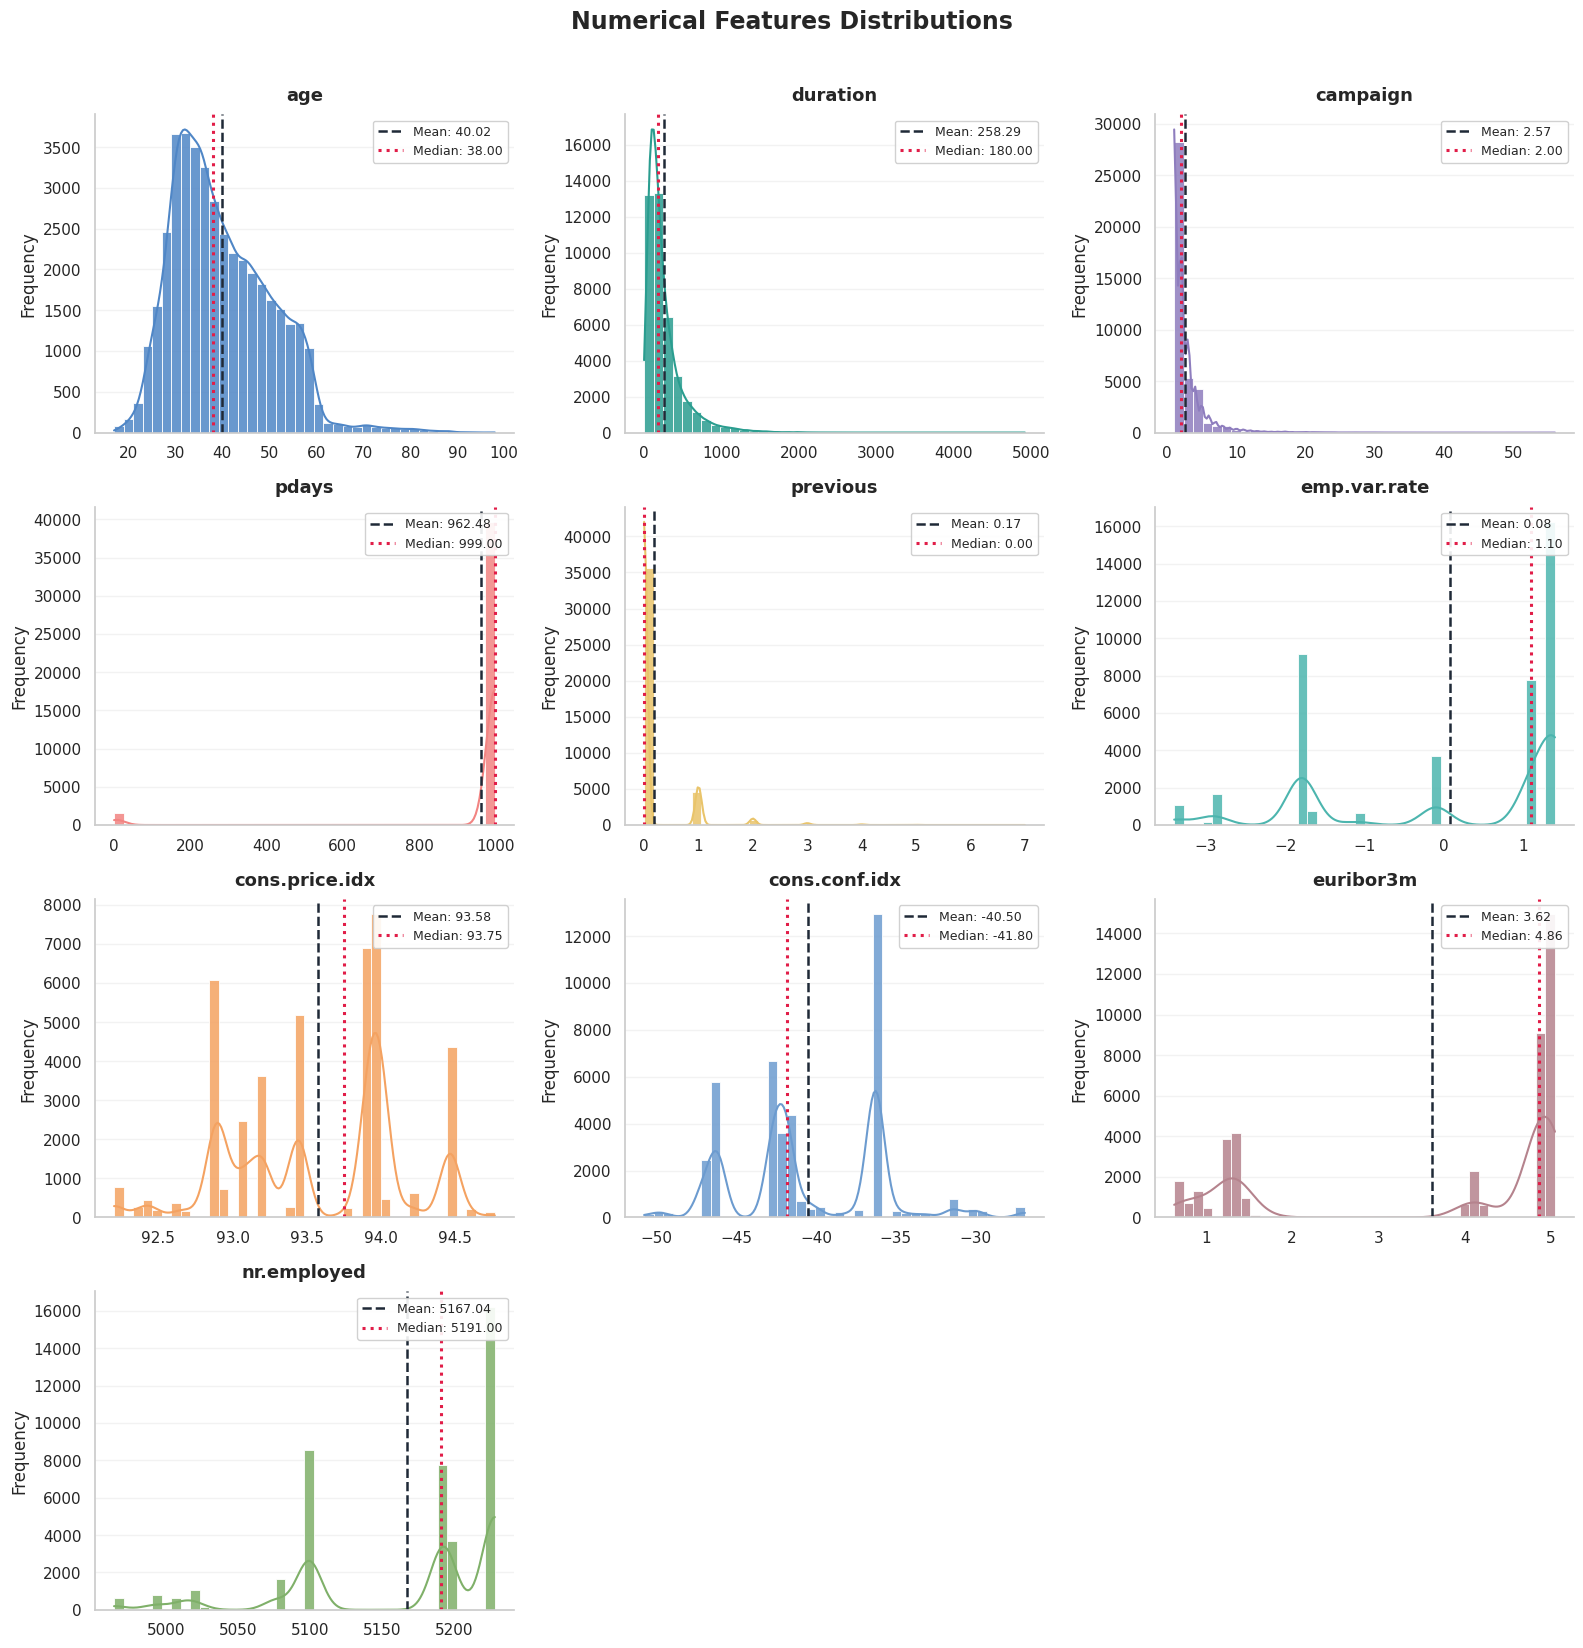

In [ ]:
# Distribution plots for numerical features
if len(numerical_cols) > 0:
    n_cols = 3
    n_rows = (len(numerical_cols) + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.2 * n_rows), squeeze=False)
    axes = axes.flatten()

    for idx, col in enumerate(numerical_cols):
        ax = axes[idx]
        color = PALETTE[idx % len(PALETTE)]

        sns.histplot(df[col], bins=40, kde=True, color=color, edgecolor='white', linewidth=0.6, alpha=0.85, ax=ax)

        ax.set_title(col, fontsize=13, fontweight='bold', pad=10)
        ax.set_xlabel('')
        ax.set_ylabel('Frequency')
        ax.grid(axis='x', visible=False)
        ax.grid(axis='y', alpha=0.25)
        sns.despine(ax=ax)

        mean_val = df[col].mean()
        median_val = df[col].median()
        ax.axvline(mean_val, color=MEAN_COLOR, linestyle='--', linewidth=1.8, label=f'Mean: {mean_val:.2f}')
        ax.axvline(median_val, color=MEDIAN_COLOR, linestyle=':', linewidth=2.2, label=f'Median: {median_val:.2f}')
        ax.legend(frameon=True, framealpha=0.9, fontsize=9, loc='upper right')

    for idx in range(len(numerical_cols), len(axes)):
        axes[idx].axis('off')

    fig.suptitle('Numerical Features Distributions', fontsize=17, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

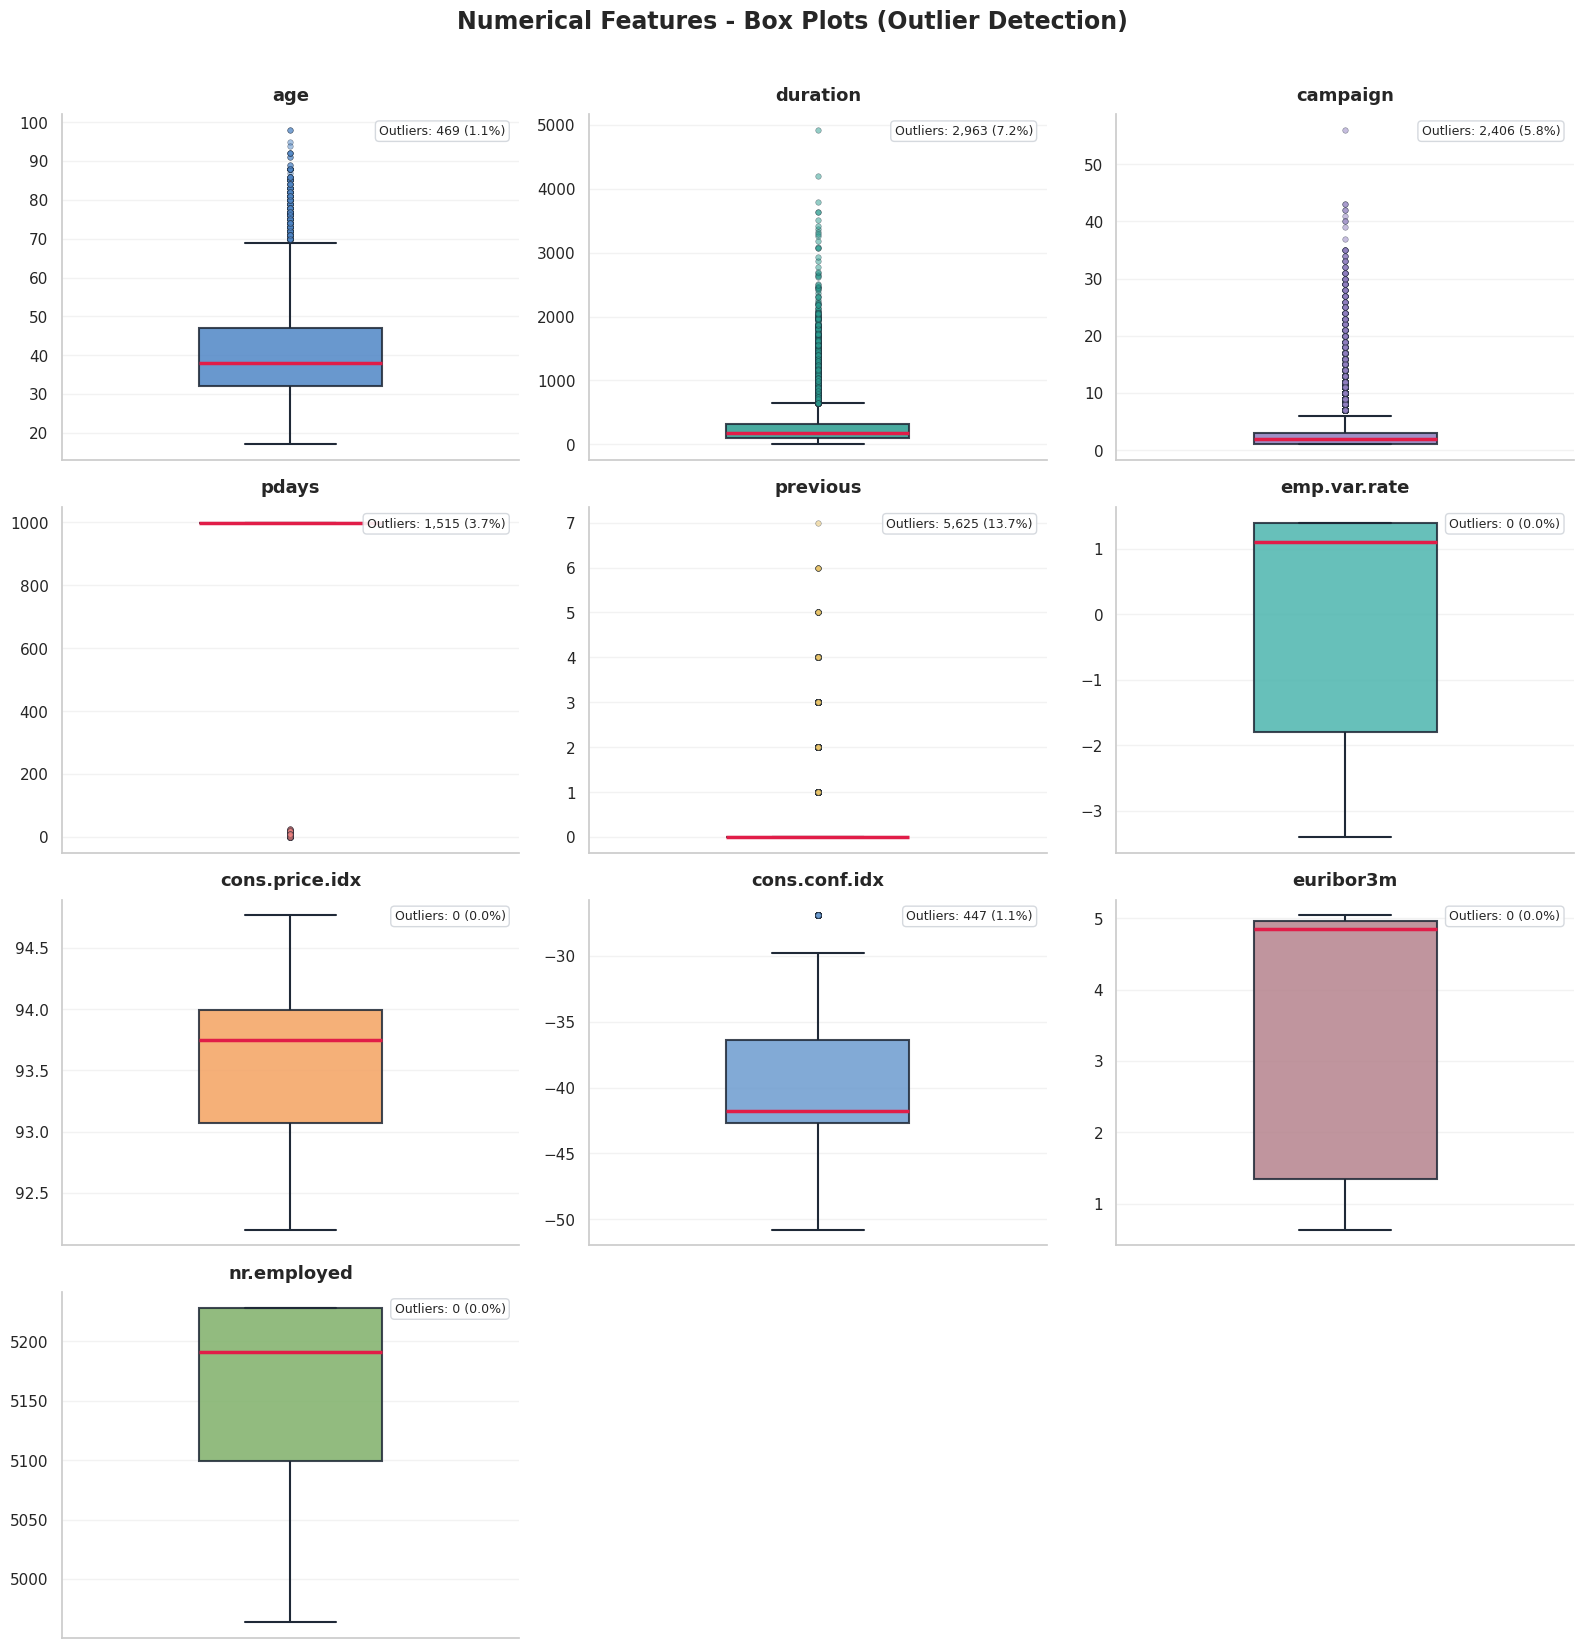

In [ ]:
# Box plots for outlier detection
if len(numerical_cols) > 0:
    n_cols = 3
    n_rows = (len(numerical_cols) + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.2 * n_rows), squeeze=False)
    axes = axes.flatten()

    for idx, col in enumerate(numerical_cols):
        ax = axes[idx]
        color = PALETTE[idx % len(PALETTE)]

        sns.boxplot(y=df[col], ax=ax, width=0.4, color=color, saturation=1,
                    linewidth=1.5,
                    boxprops=dict(edgecolor=LINE_COLOR, alpha=0.85),
                    whiskerprops=dict(color=LINE_COLOR),
                    capprops=dict(color=LINE_COLOR),
                    medianprops=dict(color=MEDIAN_COLOR, linewidth=2.5),
                    flierprops=dict(marker='o', markersize=4,
                                    markerfacecolor=color,
                                    markeredgecolor=LINE_COLOR,
                                    markeredgewidth=0.4, alpha=0.5))

        ax.set_title(col, fontsize=13, fontweight='bold', pad=10)
        ax.set_xlabel('')
        ax.set_ylabel('')
        ax.grid(axis='x', visible=False)
        ax.grid(axis='y', alpha=0.25)
        sns.despine(ax=ax)

        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
        pct = n_out / len(df) * 100
        ax.text(0.97, 0.97, f'Outliers: {n_out:,} ({pct:.1f}%)', transform=ax.transAxes, ha='right', va='top', fontsize=9, bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#D1D5DB', alpha=0.9))

    for idx in range(len(numerical_cols), len(axes)):
        axes[idx].axis('off')

    fig.suptitle('Numerical Features - Box Plots (Outlier Detection)', fontsize=17, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

In [ ]:
# Statistical summary with skewness and kurtosis
if len(numerical_cols) > 0:
    stats_summary = pd.DataFrame({
        'Feature': numerical_cols,
        'Mean': [df[col].mean() for col in numerical_cols],
        'Median': [df[col].median() for col in numerical_cols],
        'Std': [df[col].std() for col in numerical_cols],
        'Min': [df[col].min() for col in numerical_cols],
        'Max': [df[col].max() for col in numerical_cols],
        'Skewness': [df[col].skew() for col in numerical_cols],
        'Kurtosis': [df[col].kurtosis() for col in numerical_cols],
        'Outliers (IQR)': [
            len(df[(df[col] < (df[col].quantile(0.25) - 1.5 * (df[col].quantile(0.75) - df[col].quantile(0.25)))) |
                         (df[col] > (df[col].quantile(0.75) + 1.5 * (df[col].quantile(0.75) - df[col].quantile(0.25))))])
            for col in numerical_cols
        ]
    })

    display(stats_summary.style.background_gradient(cmap='coolwarm', subset=['Skewness', 'Kurtosis']))

,Feature,Mean,Median,Std,Min,Max,Skewness,Kurtosis,Outliers (IQR)
0,age,40.024060,38.000000,10.421250,17.000000,98.000000,0.784697,0.791312,469
1,duration,258.285010,180.000000,259.279249,0.000000,4918.000000,3.263141,20.247938,2963
2,campaign,2.567593,2.000000,2.770014,1.000000,56.000000,4.762507,36.979795,2406
3,pdays,962.475454,999.000000,186.910907,0.000000,999.000000,-4.922190,22.229463,1515
4,previous,0.172963,0.000000,0.494901,0.000000,7.000000,3.832042,20.108816,5625
5,emp.var.rate,0.081886,1.100000,1.570960,-3.400000,1.400000,-0.724096,-1.062632,0
6,cons.price.idx,93.575664,93.749000,0.578840,92.201000,94.767000,-0.230888,-0.829809,0
7,cons.conf.idx,-40.502600,-41.800000,4.628198,-50.800000,-26.900000,0.303180,-0.358558,447
8,euribor3m,3.621291,4.857000,1.734447,0.634000,5.045000,-0.709188,-1.406803,0
9,nr.employed,5167.035911,5191.000000,72.251528,4963.600000,5228.100000,-1.044262,-0.003760,0


## Categorical feature analysis

In [ ]:
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Found {len(categorical_cols)} categorical features: {categorical_cols}")

Found 11 categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


In [ ]:
# Value counts for categorical features
if len(categorical_cols) > 0:
    for col in categorical_cols:
        value_counts = df[col].value_counts()
        print(f"Unique values: {df[col].nunique()}")
        print(f"Most common: {value_counts.index[0]} ({value_counts.iloc[0]} occurrences)")
        print()
        print("Top 10 values:")
        display(pd.DataFrame({
            'Value': value_counts.head(10).index,
            'Count': value_counts.head(10).values,
            'Percentage': (value_counts.head(10) / len(df) * 100).values
        }))
        print()

Unique values: 12
Most common: admin. (10422 occurrences)

Top 10 values:


,Value,Count,Percentage
0,admin.,10422,25.303486
1,blue-collar,9254,22.467709
2,technician,6743,16.371273
3,services,3969,9.636302
4,management,2924,7.099155
5,retired,1720,4.175974
6,entrepreneur,1456,3.535010
7,self-employed,1421,3.450034
8,housemaid,1060,2.573565
9,unemployed,1014,2.461882



Unique values: 4
Most common: married (24928 occurrences)

Top 10 values:


,Value,Count,Percentage
0,married,24928,60.522482
1,single,11568,28.085850
2,divorced,4612,11.197436
3,unknown,80,0.194231



Unique values: 8
Most common: university.degree (12168 occurrences)

Top 10 values:


,Value,Count,Percentage
0,university.degree,12168,29.542585
1,high.school,9515,23.101389
2,basic.9y,6045,14.676605
3,professional.course,5243,12.729436
4,basic.4y,4176,10.138875
5,basic.6y,2292,5.564728
6,unknown,1731,4.202680
7,illiterate,18,0.043702


... (12 outputs left out)


Unique values: 3
Most common: nonexistent (35563 occurrences)

Top 10 values:


,Value,Count,Percentage
0,nonexistent,35563,86.343110
1,failure,4252,10.323395
2,success,1373,3.333495



Unique values: 2
Most common: no (36548 occurrences)

Top 10 values:


,Value,Count,Percentage
0,no,36548,88.734583
1,yes,4640,11.265417


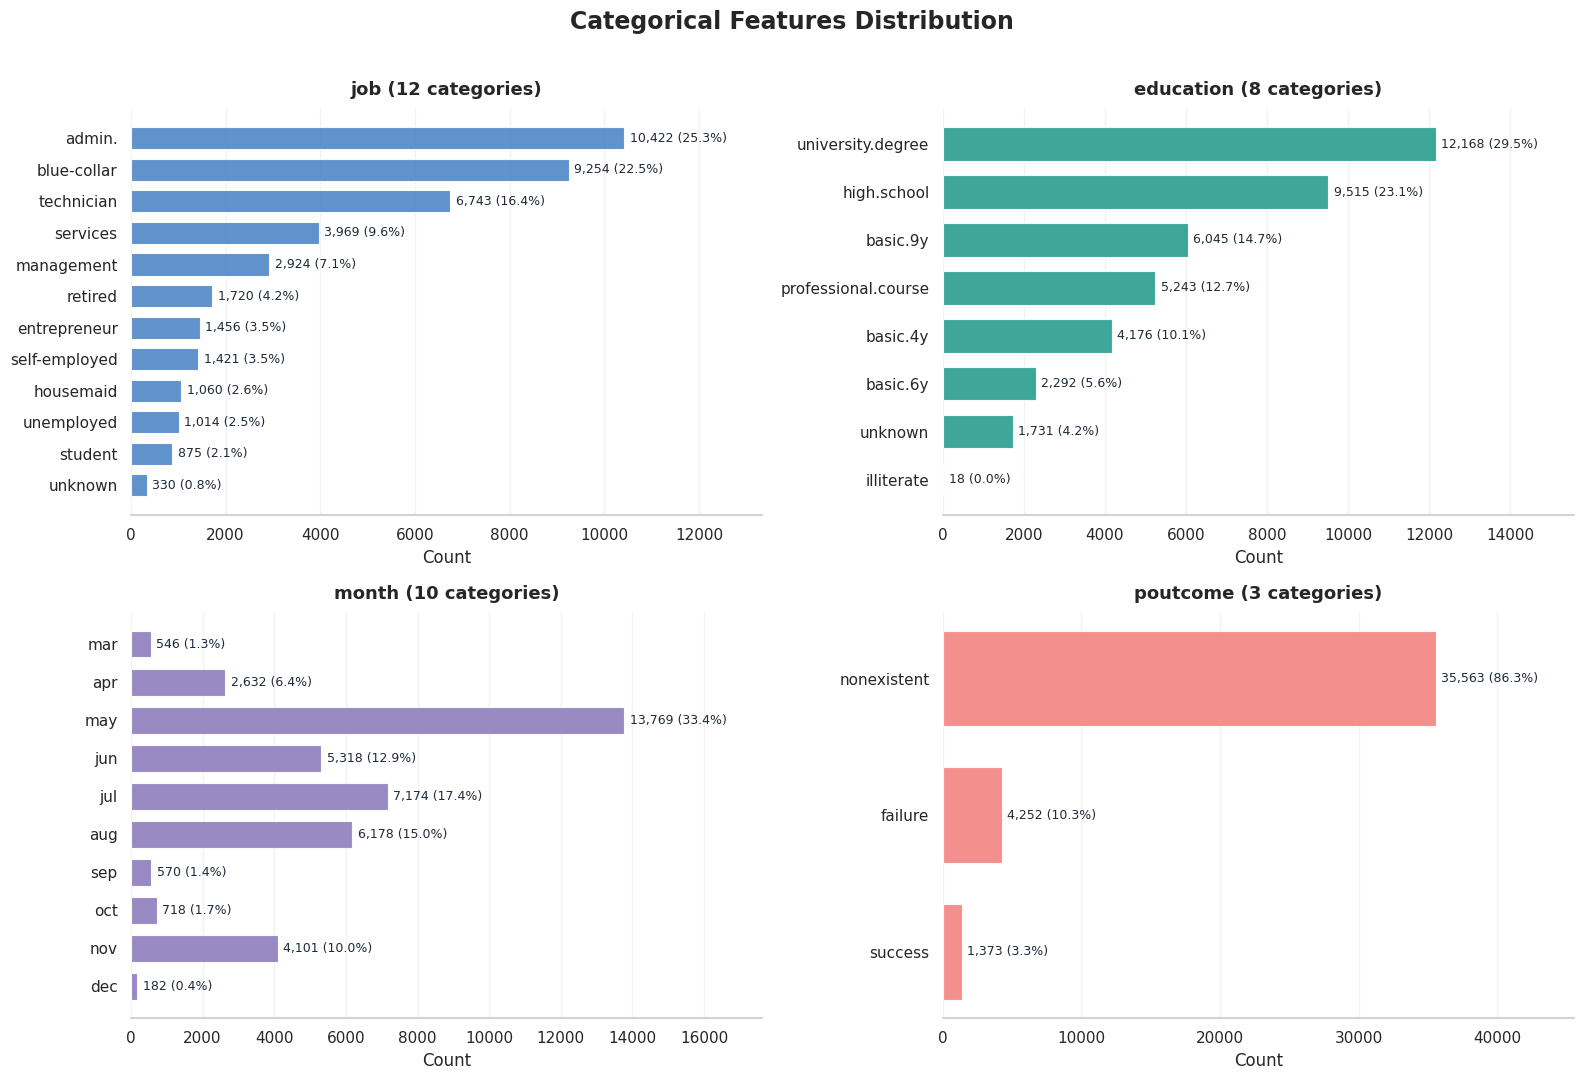

In [ ]:
cat_plot_cols = ['job', 'education', 'month', 'poutcome']
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
total = len(df)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()

for idx, col in enumerate(cat_plot_cols):
    ax = axes[idx]
    counts = df[col].value_counts()

    if col == 'month':
        counts = counts.reindex([m for m in month_order if m in counts.index])
        counts = counts.iloc[::-1]
    else:
        counts = counts.sort_values(ascending=True)

    bars = ax.barh(counts.index.astype(str), counts.values, color=PALETTE[idx],
                   edgecolor='white', linewidth=0.8, alpha=0.9, height=0.7)
    ax.bar_label(bars, labels=[f'{v:,} ({v / total:.1%})' for v in counts.values],
                 padding=4, fontsize=9, color='#1F2937')

    ax.set_xlim(0, counts.max() * 1.28)
    ax.set_title(f'{col} ({len(counts)} categories)', fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel('Count')
    ax.set_ylabel('')
    ax.grid(axis='y', visible=False)
    ax.grid(axis='x', alpha=0.25)
    sns.despine(ax=ax, left=True)

fig.suptitle('Categorical Features Distribution', fontsize=17, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## Target feature anaysis

Data Type: object
Unique Values: 2

Value Distribution:


,Value,Count,Percentage
0,no,36548,88.734583
1,yes,4640,11.265417


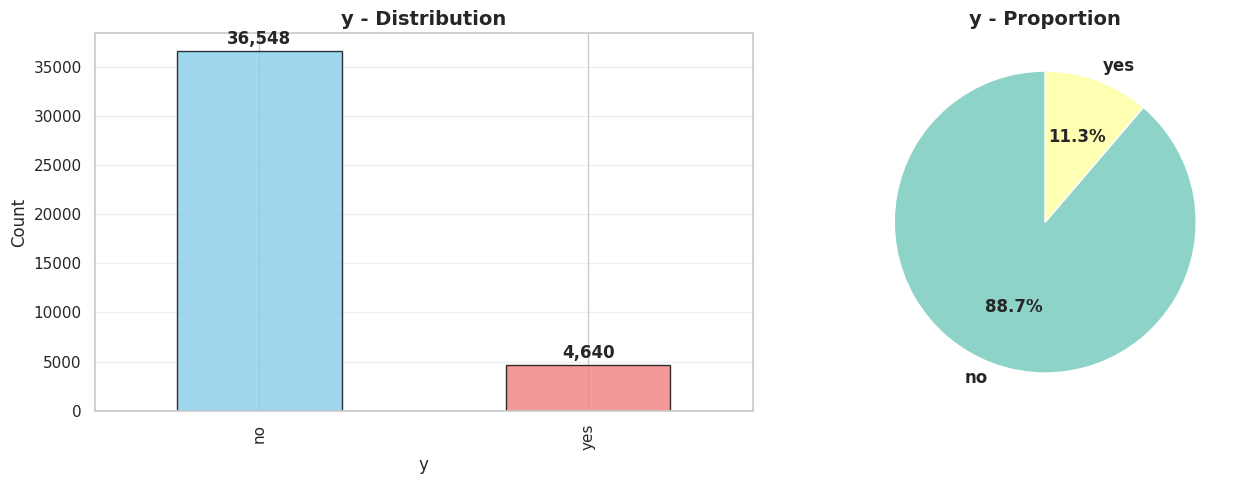


Class Balance Ratio: 0.127
Dataset is imbalanced


In [ ]:
if target_col in df.columns:
    target_counts = df[target_col].value_counts()
    print(f"Data Type: {df[target_col].dtype}")
    print(f"Unique Values: {df[target_col].nunique()}")
    print()
    print("Value Distribution:")
    display(pd.DataFrame({
        'Value': target_counts.index,
        'Count': target_counts.values,
        'Percentage': (target_counts / len(df) * 100).values
    }))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    target_counts.plot(kind='bar', ax=axes[0], color=['skyblue', 'lightcoral', 'lightgreen'][:len(target_counts)],
                      edgecolor='black', alpha=0.8)
    axes[0].set_title(f'{target_col} - Distribution', fontsize=14, fontweight='bold')
    axes[0].set_xlabel(target_col)
    axes[0].set_ylabel('Count')
    axes[0].grid(axis='y', alpha=0.3)

    for i, v in enumerate(target_counts.values):
        axes[0].text(i, v + max(target_counts) * 0.01, f'{v:,}', ha='center', va='bottom', fontweight='bold')

    colors = plt.cm.Set3(range(len(target_counts)))
    axes[1].pie(target_counts.values, labels=target_counts.index, autopct='%1.1f%%',
                startangle=90, colors=colors, textprops={'fontsize': 12, 'fontweight': 'bold'})
    axes[1].set_title(f'{target_col} - Proportion', fontsize=14, fontweight='bold')

    plt.tight_layout()
    plt.show()

    if df[target_col].nunique() <= 10:
        balance_ratio = target_counts.min() / target_counts.max()
        print(f"\nClass Balance Ratio: {balance_ratio:.3f}")
        if balance_ratio < 0.5:
            print("Dataset is imbalanced")
        else:
            print("Dataset is relatively balanced")
else:
    print(f"Target column '{target_col}' not found in training data")

## Correlation analysis

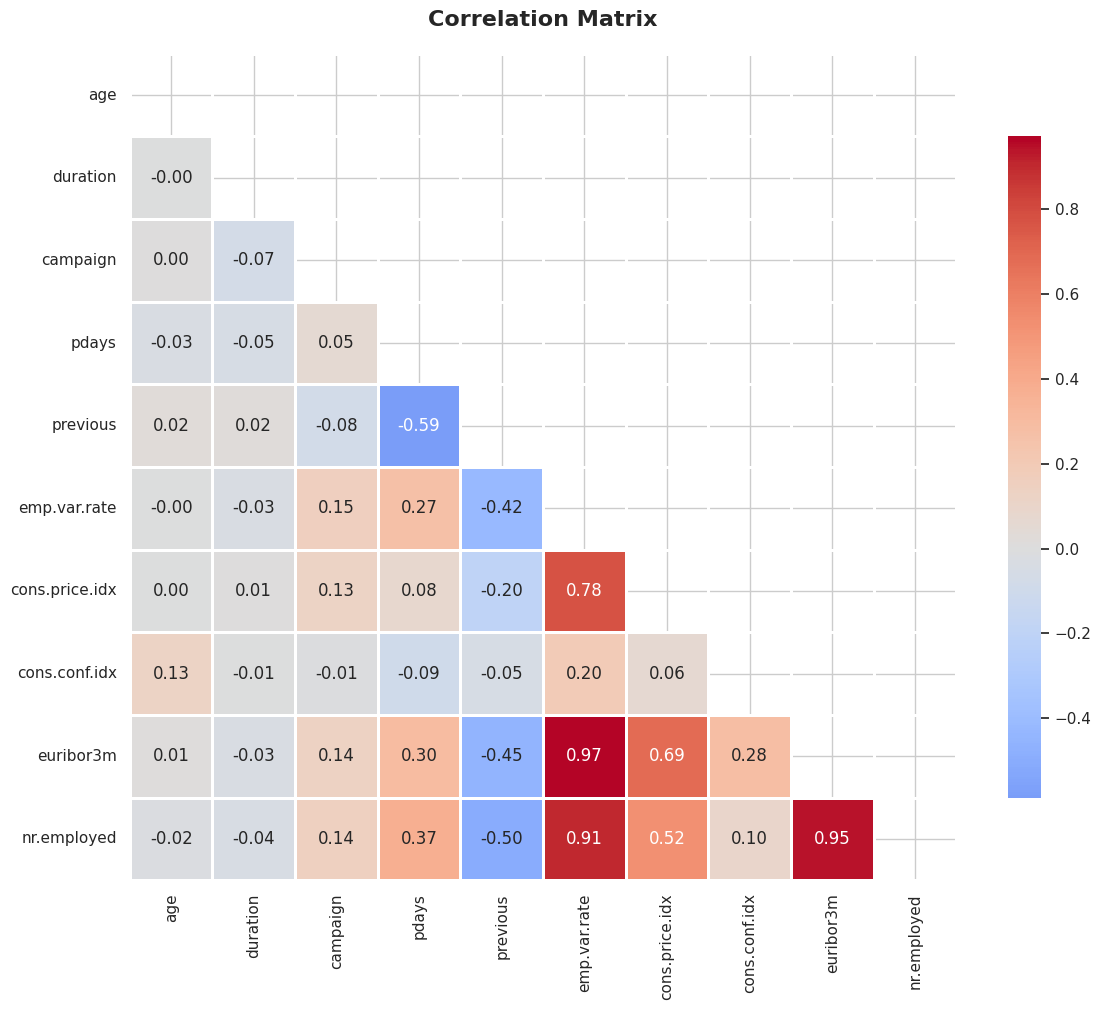

,Feature 1,Feature 2,Correlation
1,emp.var.rate,euribor3m,0.972245
3,euribor3m,nr.employed,0.945154
2,emp.var.rate,nr.employed,0.906970
0,emp.var.rate,cons.price.idx,0.775334


In [ ]:
# Correlation matrix for numerical features
if len(numerical_cols) > 0:
    # Include target if numerical
    corr_cols = numerical_cols.copy()
    if target_col in df.columns and df[target_col].dtype in ['int64', 'float64']:
        corr_cols.append(target_col)

    correlation_matrix = df[corr_cols].corr()

    plt.figure(figsize=(12, 10))
    mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
    sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
                center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
    plt.title('Correlation Matrix', fontsize=16, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.show()

    # Highly correlated features
    high_corr = []
    for i in range(len(correlation_matrix.columns)):
        for j in range(i+1, len(correlation_matrix.columns)):
            if abs(correlation_matrix.iloc[i, j]) > 0.7:
                high_corr.append({
                    'Feature 1': correlation_matrix.columns[i],
                    'Feature 2': correlation_matrix.columns[j],
                    'Correlation': correlation_matrix.iloc[i, j]
                })

    if high_corr:
        display(pd.DataFrame(high_corr).sort_values('Correlation', key=abs, ascending=False))
    else:
        print("No highly correlated features found")

Target 'y' di-encode: no = 0, yes = 1


Feature,Correlation,Abs_Correlation
duration,+0.405,0.405
nr.employed,-0.355,0.355
pdays,-0.325,0.325
euribor3m,-0.308,0.308
emp.var.rate,-0.298,0.298
previous,+0.230,0.230
cons.price.idx,-0.136,0.136
campaign,-0.066,0.066
cons.conf.idx,+0.055,0.055
age,+0.030,0.030


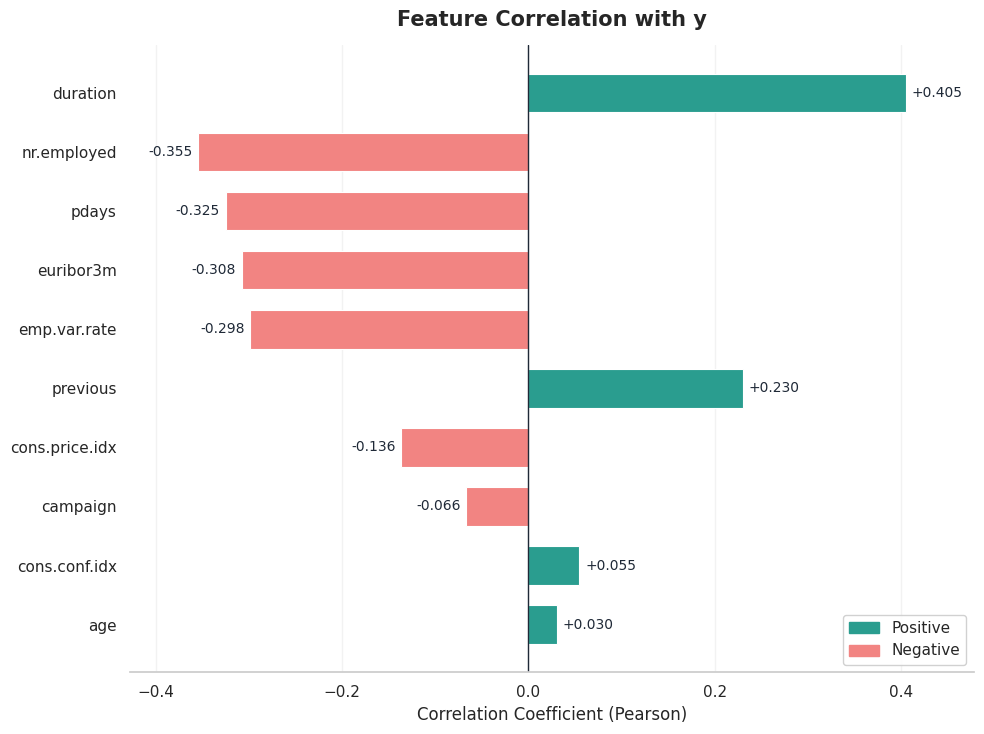

In [ ]:
# Correlation with target variable
if target_col in df.columns and len(numerical_cols) > 0:
    target_series = df[target_col]

    # Convert non-numeric target to numeric codes for correlation analysis
    if not pd.api.types.is_numeric_dtype(target_series):
        unique_count = target_series.nunique(dropna=True)
        if unique_count <= 20:
            values = set(target_series.dropna().astype(str).str.lower().unique())
            if values <= {'yes', 'no'}:
                target_numeric = target_series.astype(str).str.lower().map({'no': 0, 'yes': 1})
                print(f"Target '{target_col}' di-encode: no = 0, yes = 1")
            else:
                codes, uniques = pd.factorize(target_series)
                target_numeric = pd.Series(codes, index=df.index)
                mapping = {u: i for i, u in enumerate(uniques)}
                print(f"Target '{target_col}' (unique={unique_count}): {mapping}")
        else:
            target_numeric = None
            print(f"Target '{target_col}' has too many categories ({unique_count}); skipping target correlation")
    else:
        target_numeric = target_series

    if target_numeric is not None:
        corr_frame = df[numerical_cols].copy()
        corr_frame[target_col] = target_numeric
        target_corr = corr_frame.corr()[target_col].drop(target_col)

        corr_table = pd.DataFrame({
            'Feature': target_corr.index,
            'Correlation': target_corr.values,
            'Abs_Correlation': target_corr.abs().values
        }).sort_values('Abs_Correlation', ascending=False).reset_index(drop=True)

        lim = corr_table['Abs_Correlation'].max()
        display(corr_table.style
                .background_gradient(subset=['Correlation'], cmap=TABLE_CMAP, vmin=-lim, vmax=lim)
                .background_gradient(subset=['Abs_Correlation'], cmap='Blues', vmin=0, vmax=lim)
                .format({'Correlation': '{:+.3f}', 'Abs_Correlation': '{:.3f}'})
                .hide(axis='index'))

        plot_series = target_corr.reindex(target_corr.abs().sort_values().index)
        colors = [POS_COLOR if x > 0 else NEG_COLOR for x in plot_series.values]

        fig, ax = plt.subplots(figsize=(10, 0.55 * len(plot_series) + 2))
        bars = ax.barh(plot_series.index, plot_series.values, color=colors,
                       edgecolor='white', linewidth=0.8, height=0.65)
        ax.bar_label(bars, labels=[f'{v:+.3f}' for v in plot_series.values],
                     padding=4, fontsize=10, color='#1F2937')

        ax.axvline(0, color='#1F2937', linewidth=1)
        ax.set_title(f'Feature Correlation with {target_col}', fontsize=15, fontweight='bold', pad=14)
        ax.set_xlabel('Correlation Coefficient (Pearson)')
        ax.set_ylabel('')
        ax.grid(axis='y', visible=False)
        ax.grid(axis='x', alpha=0.25)

        pad = lim * 0.18
        ax.set_xlim(min(plot_series.min(), 0) - pad, max(plot_series.max(), 0) + pad)
        sns.despine(ax=ax, left=True)

        from matplotlib.patches import Patch
        ax.legend(handles=[Patch(color=POS_COLOR, label='Positive'), Patch(color=NEG_COLOR, label='Negative')], loc='lower right', frameon=True, framealpha=0.9)

        plt.tight_layout()
        plt.show()
else:
    print(f"Cannot compute target correlation. target_col='{target_col}', exists={target_col in df.columns}, numerical_cols={len(numerical_cols)}")

# Data preprocessing

In [ ]:
SEED = 42
USE_DURATION = False

data = df.copy()

# Remove duplicate rows
n_before = len(data)
data = data.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {n_before - len(data)} rows -> {len(data):,} rows remain")

# Encode the target explicitly: yes = 1, no = 0
y_all = data[target_col].map({'no': 0, 'yes': 1}).astype(int)
X_all = data.drop(columns=[target_col])

# Drop duration
if not USE_DURATION:
    X_all = X_all.drop(columns=['duration'])

# Feature engineering: was_contacted_before = 0/1
def add_features(d):
    d = d.copy()
    d['was_contacted_before'] = (d['pdays'] != 999).astype(int)
    d['pdays'] = d['pdays'].where(d['pdays'] != 999, 0)
    return d

X_all = add_features(X_all)

# Define column groups
cat_cols  = X_all.select_dtypes(exclude=np.number).columns.tolist()
skew_cols = ['campaign', 'previous']
num_cols  = [c for c in X_all.select_dtypes(include=np.number).columns
             if c not in skew_cols + ['was_contacted_before']]
bin_cols  = ['was_contacted_before']

print(f"\nCategorical ({len(cat_cols)}): {cat_cols}")
print(f"Numerical ({len(num_cols)}): {num_cols}")
print(f"Long-tailed numerical -> log1p ({len(skew_cols)}): {skew_cols}")
print(f"Binary: {bin_cols}")
print(f"\nPositive class ('yes') rate: {y_all.mean():.2%}  | Feature matrix shape: {X_all.shape}")

Duplicates removed: 12 rows -> 41,176 rows remain

Categorical (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numerical (7): ['age', 'pdays', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Long-tailed numerical -> log1p (2): ['campaign', 'previous']
Binary: ['was_contacted_before']

Positive class ('yes') rate: 11.27%  | Feature matrix shape: (41176, 20)


In [ ]:
SPLIT_MODE = 'time'
TEST_SIZE = 0.20

if SPLIT_MODE == 'time':
    split_idx = int(len(X_all) * (1 - TEST_SIZE))
    X_train, X_test = X_all.iloc[:split_idx].copy(), X_all.iloc[split_idx:].copy()
    y_train, y_test = y_all.iloc[:split_idx].copy(), y_all.iloc[split_idx:].copy()
else:
    from sklearn.model_selection import train_test_split
    X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=TEST_SIZE,
                                                        stratify=y_all, random_state=SEED)
    X_train, y_train = X_train.sort_index(), y_train.sort_index()
    X_test, y_test = X_test.sort_index(), y_test.sort_index()

summary = pd.DataFrame({
    'Set': ['Train', 'Test'],
    'Rows': [len(X_train), len(X_test)],
    "'yes' rate": [y_train.mean(), y_test.mean()],
    'Mean euribor3m': [X_train['euribor3m'].mean(), X_test['euribor3m'].mean()], # suku bunga acuan harian yang menunjukkan rata rata suku bunga pinjaman tanpa jaminan antar bank di zona euro
})
print(f"Split mode: {SPLIT_MODE}")
display(summary.style.format({"'yes' rate": '{:.2%}', 'Mean euribor3m': '{:.2f}'}).hide(axis='index'))

Split mode: time


Set,Rows,'yes' rate,Mean euribor3m
Train,32940,6.38%,4.27
Test,8236,30.83%,1.03


In [ ]:
def make_preprocessor(scale=True):
    num_steps = [('scaler', StandardScaler())] if scale else [('identity', FunctionTransformer(feature_names_out='one-to-one'))]
    skew_steps = [('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one'))] + num_steps
    return ColumnTransformer([
        ('cat',  OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False), cat_cols),
        ('num',  Pipeline(num_steps),  num_cols),
        ('skew', Pipeline(skew_steps), skew_cols),
        ('bin',  'passthrough', bin_cols),
    ])

def build_models():
    return {
        'Logistic Regression': Pipeline([('prep', make_preprocessor(True)), ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED))]),
        'Decision Tree': Pipeline([('prep', make_preprocessor(False)), ('clf', DecisionTreeClassifier(class_weight='balanced', random_state=SEED))]),
        'SVM (RBF)': Pipeline([('prep', make_preprocessor(True)), ('clf', SVC(kernel='rbf', C=3, gamma='scale', class_weight='balanced', random_state=SEED))]),
    }

MODEL_NAMES = list(build_models().keys())
MODEL_COLORS = dict(zip(MODEL_NAMES, PALETTE))
print("Models to compare:", MODEL_NAMES)

Models to compare: ['Logistic Regression', 'Decision Tree', 'SVM (RBF)']


# Hyperparameter tuning

In [ ]:
def get_scores(model, X):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def alift(y_true, y_score):
    y_true = np.asarray(y_true)
    order = np.argsort(-np.asarray(y_score), kind='mergesort')
    gains = np.cumsum(y_true[order]) / y_true.sum()
    x = np.arange(1, len(gains) + 1) / len(gains)
    return auc(np.r_[0, x], np.r_[0, gains])

def capture_at(y_true, y_score, frac):
    y_true = np.asarray(y_true)
    order = np.argsort(-np.asarray(y_score), kind='mergesort')
    k = int(np.ceil(frac * len(y_true)))
    return y_true[order][:k].sum() / y_true.sum()

def evaluate(model, X, y):
    s = get_scores(model, X)
    pred = model.predict(X)
    return {
        'AUC': roc_auc_score(y, s),
        'ALIFT': alift(y, s),
        'PR-AUC': average_precision_score(y, s),
        'Precision': precision_score(y, pred, zero_division=0),
        'Recall': recall_score(y, pred),
        'F1': f1_score(y, pred),
        'Balanced Acc': balanced_accuracy_score(y, pred),
        'MCC': matthews_corrcoef(y, pred),
        'Capture@50%': capture_at(y, s, 0.5),
    }

In [ ]:
TUNE_CV = TimeSeriesSplit(n_splits=4)
SVM_TUNE_STEP = 8

PARAM_GRIDS = {
    'Logistic Regression': {'clf__C': [0.01, 0.1, 1, 10]},
    'Decision Tree': {'clf__max_depth': [3, 5, 7, 10], 'clf__min_samples_leaf': [20, 50, 100], 'clf__criterion': ['gini', 'entropy']},
    'SVM (RBF)': {'clf__gamma': [2.0 ** k for k in (-15, -11.4, -7.8, -4.2, -0.6, 3)]},
}

best_params, tune_summary = {}, []
t0 = time.time()
for name in MODEL_NAMES:
    if name.startswith('SVM'):
        Xt, yt = X_train.iloc[::SVM_TUNE_STEP], y_train.iloc[::SVM_TUNE_STEP]
    else:
        Xt, yt = X_train, y_train
    gs = GridSearchCV(build_models()[name], PARAM_GRIDS[name], scoring='roc_auc',
                      cv=TUNE_CV, n_jobs=-1, refit=False)
    gs.fit(Xt, yt)
    i = int(np.argmax(gs.cv_results_['mean_test_score']))
    best_params[name] = gs.cv_results_['params'][i]
    tune_summary.append({
        'Model': name,
        'CV AUC (mean)': gs.cv_results_['mean_test_score'][i],
        'CV AUC (std)': gs.cv_results_['std_test_score'][i],
        'Best params': {k.replace('clf__', ''): v for k, v in best_params[name].items()}
    })
    print(f"{name:20s} done ({time.time()-t0:.0f}s)")

display(pd.DataFrame(tune_summary).style.format({'CV AUC (mean)': '{:.3f}', 'CV AUC (std)': '{:.3f}'}).hide(axis='index'))

Logistic Regression  done (5s)
Decision Tree        done (23s)
SVM (RBF)            done (34s)


Model,CV AUC (mean),CV AUC (std),Best params
Logistic Regression,0.513,0.047,{'C': 0.1}
Decision Tree,0.525,0.054,"{'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 100}"
SVM (RBF),0.540,0.024,{'gamma': 0.0003700479898707026}


# Modelling

In [ ]:
N_RUNS = 10
SVM_SUBSAMPLE = 8000

sss = StratifiedShuffleSplit(n_splits=N_RUNS, test_size=1/3, random_state=SEED)
phase1_rows = []
t0 = time.time()
for run, (tr, va) in enumerate(sss.split(X_train, y_train), 1):
    for name in MODEL_NAMES:
        tr_idx = tr
        if name.startswith('SVM') and SVM_SUBSAMPLE and len(tr) > SVM_SUBSAMPLE:
            tr_idx = np.random.RandomState(SEED + run).choice(tr, SVM_SUBSAMPLE, replace=False)
        m = build_models()[name].set_params(**best_params[name])
        m.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        phase1_rows.append({'Run': run, 'Model': name, **evaluate(m, X_train.iloc[va], y_train.iloc[va])})
    print(f"Run {run}/{N_RUNS} done ({time.time()-t0:.0f}s)", end='\r')

phase1 = pd.DataFrame(phase1_rows)
agg = phase1.groupby('Model')[['AUC', 'ALIFT', 'PR-AUC', 'F1', 'Recall', 'Precision']].agg(['mean', 'std']).round(3)
print(f"\n\nModeling phase results (mean and std over {N_RUNS} runs):")
display(agg.loc[MODEL_NAMES])

best1 = phase1.groupby('Model')['AUC'].mean().idxmax()
print(f"\nBest model in the modeling phase (AUC): {best1}")
for name in MODEL_NAMES:
    if name != best1:
        p = mannwhitneyu(phase1.loc[phase1.Model == best1, 'AUC'], phase1.loc[phase1.Model == name, 'AUC']).pvalue
        print(f"  {best1} vs {name}: p = {p:.4f} -> {'significant' if p < 0.05 else 'not significant'} (alpha 0.05)")

Run 10/10 done (238s)

Modeling phase results (mean and std over 10 runs):


AUC         ALIFT        PR-AUC            F1         \
                      mean    std   mean    std   mean    std   mean    std   
Model                                                                         
Logistic Regression  0.668  0.005  0.657  0.005  0.187  0.005  0.188  0.006   
Decision Tree        0.655  0.010  0.645  0.008  0.172  0.009  0.184  0.015   
SVM (RBF)            0.649  0.011  0.640  0.010  0.166  0.013  0.204  0.007   

                    Recall        Precision         
                      mean    std      mean    std  
Model                                               
Logistic Regression  0.480  0.025     0.117  0.005  
Decision Tree        0.458  0.049     0.116  0.015  
SVM (RBF)            0.358  0.012     0.143  0.005


Best model in the modeling phase (AUC): Logistic Regression
  Logistic Regression vs Decision Tree: p = 0.0058 -> significant (alpha 0.05)
  Logistic Regression vs SVM (RBF): p = 0.0008 -> significant (alpha 0.05)


# Eval

In [ ]:
final_models, test_rows = {}, []
t0 = time.time()
for name in MODEL_NAMES:
    m = build_models()[name].set_params(**best_params[name])
    m.fit(X_train, y_train)
    final_models[name] = m
    test_rows.append({'Model': name, **evaluate(m, X_test, y_test)})
    print(f"{name:20s} trained ({time.time()-t0:.0f}s)")

test_results = pd.DataFrame(test_rows).set_index('Model')
print("\nTest set results:")
display(test_results.style.format('{:.3f}').highlight_max(color='#359FA0', axis=0))
print()

paper_ref = pd.DataFrame({'AUC': [0.715, 0.757, 0.767], 'ALIFT': [0.626, 0.651, 0.656]}, index=['LR', 'DT', 'SVM'])
display(paper_ref)

Logistic Regression  trained (1s)
Decision Tree        trained (1s)
SVM (RBF)            trained (164s)

Test set results:


,AUC,ALIFT,PR-AUC,Precision,Recall,F1,Balanced Acc,MCC,Capture@50%
Model,,,,,,,,,
Logistic Regression,0.740,0.666,0.539,0.350,0.933,0.509,0.581,0.195,0.747
Decision Tree,0.547,0.495,0.371,0.581,0.267,0.366,0.591,0.240,0.456
SVM (RBF),0.713,0.647,0.470,0.308,1.000,0.471,0.500,0.000,0.737


,AUC,ALIFT
LR,0.715,0.626
DT,0.757,0.651
SVM,0.767,0.656


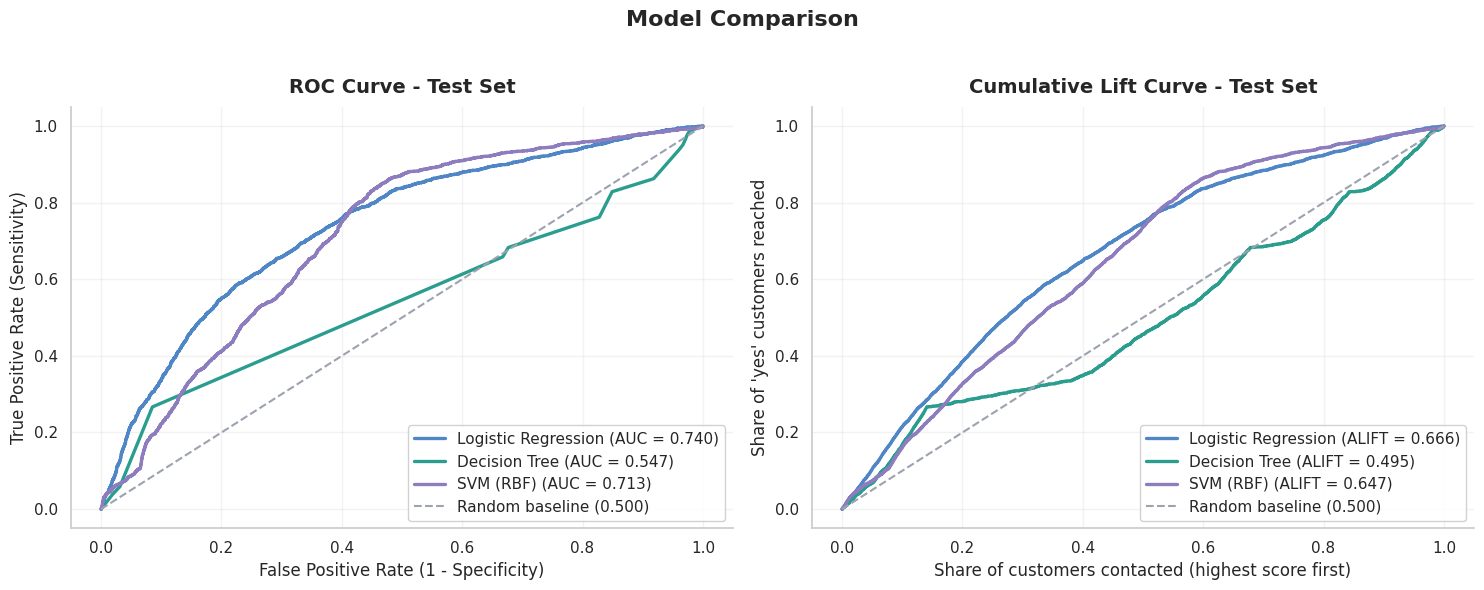

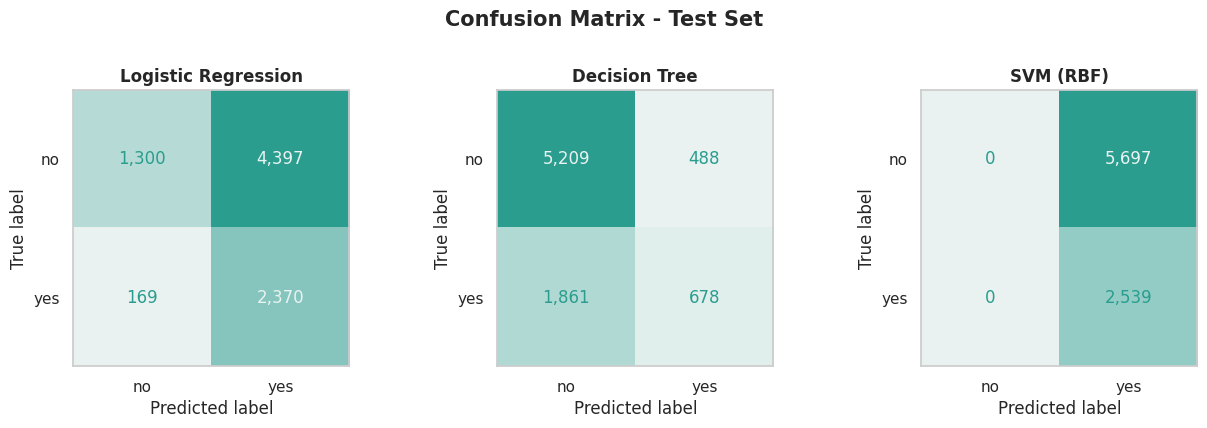

In [ ]:
scores_test = {n: get_scores(m, X_test) for n, m in final_models.items()}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ROC curve
ax = axes[0]
for n, s in scores_test.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    ax.plot(fpr, tpr, color=MODEL_COLORS[n], linewidth=2.4, label=f'{n} (AUC = {roc_auc_score(y_test, s):.3f})')
ax.plot([0, 1], [0, 1], color='#9CA3AF', linestyle='--', linewidth=1.5, label='Random baseline (0.500)')
ax.set_title('ROC Curve - Test Set', fontsize=14, fontweight='bold', pad=10)
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Sensitivity)')
ax.legend(loc='lower right', frameon=True, framealpha=0.9)
ax.grid(alpha=0.25); sns.despine(ax=ax)

# Cumulative lift curve
ax = axes[1]
for n, s in scores_test.items():
    order = np.argsort(-s, kind='mergesort')
    gains = np.cumsum(y_test.values[order]) / y_test.sum()
    x = np.arange(1, len(gains) + 1) / len(gains)
    ax.plot(np.r_[0, x], np.r_[0, gains], color=MODEL_COLORS[n], linewidth=2.4,
            label=f'{n} (ALIFT = {alift(y_test, s):.3f})')
ax.plot([0, 1], [0, 1], color='#9CA3AF', linestyle='--', linewidth=1.5, label='Random baseline (0.500)')
ax.set_title('Cumulative Lift Curve - Test Set', fontsize=14, fontweight='bold', pad=10)
ax.set_xlabel('Share of customers contacted (highest score first)')
ax.set_ylabel("Share of 'yes' customers reached")
ax.legend(loc='lower right', frameon=True, framealpha=0.9)
ax.grid(alpha=0.25); sns.despine(ax=ax)

fig.suptitle("Model Comparison", fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()
print()

cm_cmap = sns.light_palette('#2A9D8F', as_cmap=True)
fig, axes = plt.subplots(1, len(final_models), figsize=(4.3 * len(final_models), 4.2), squeeze=False)
for ax, (n, m) in zip(axes[0], final_models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)), display_labels=['no', 'yes']).plot(ax=ax, cmap=cm_cmap, colorbar=False, values_format=',d')
    ax.set_title(n, fontsize=12, fontweight='bold')
    ax.grid(False)
fig.suptitle('Confusion Matrix - Test Set', fontsize=15, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

In [ ]:
fracs = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
lift_table = pd.DataFrame(
    {n: [capture_at(y_test, s, f) for f in fracs] for n, s in scores_test.items()},
    index=[f'{int(f*100)}%' for f in fracs])
lift_table.index.name = 'Customers contacted'
lift_table['Random baseline'] = fracs

print("Share of 'yes' customers successfully reached:")
display(lift_table.style.format('{:.1%}').highlight_max(color='#359FA0', axis=1))

Share of 'yes' customers successfully reached:


,Logistic Regression,Decision Tree,SVM (RBF),Random baseline
Customers contacted,,,,
5%,10.4%,6.8%,7.3%,5.0%
10%,21.5%,16.8%,16.1%,10.0%
20%,38.5%,28.1%,32.8%,20.0%
30%,54.0%,31.1%,46.4%,30.0%
40%,64.8%,34.9%,58.9%,40.0%
50%,74.7%,45.6%,73.7%,50.0%
60%,83.7%,55.7%,86.4%,60.0%
70%,88.4%,68.5%,91.2%,70.0%
